In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:


PROJECT_DIR = Path(
    "/rs1/researchers/a/amallav/species_classification/ecological_informatics"
)

BATCH_DIR = (
    PROJECT_DIR
    / "notebooks/object_detection/output/batch_runs"
)

ANALYSIS_DIR = (
    PROJECT_DIR
    / "notebooks/object_detection/output/analysis"
)

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)


In [3]:

batch_dirs = sorted(BATCH_DIR.glob("batch_*"))

detection_files = []
manifest_files = []

for batch_dir in batch_dirs:
    detection_files.extend(
        sorted(batch_dir.glob("detections_*.parquet"))
    )

    manifest_path = batch_dir / "manifest.parquet"

    if manifest_path.exists():
        manifest_files.append(manifest_path)

print("Batch directories:", len(batch_dirs))
print("Detection checkpoint files:", len(detection_files))
print("Manifest files:", len(manifest_files))

for batch_dir in batch_dirs:
    print(batch_dir.name)


Batch directories: 3
Detection checkpoint files: 231
Manifest files: 3
batch_000
batch_001
batch_002


In [4]:

if not detection_files:
    raise FileNotFoundError("No detection checkpoint files found.")

detections_df = pd.concat(
    [pd.read_parquet(path) for path in detection_files],
    ignore_index=True
)

print("Combined detection rows:", len(detections_df))
print("Columns:", len(detections_df.columns))

display(detections_df.head())


Combined detection rows: 29958
Columns: 60


,obs_id,photo_id,photo_license_code,photo_url,obs_url,quality_grade,obs_license_code,predator_prey_role,scientific_name,taxon_rank,...,x0,y0,x1,y1,box_area_frac,aspect_ratio,edge_proximity_frac,center_offset_frac,is_valid_box,score_rank_gap
0,338604,421440,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,346.806824,387.015900,919.592834,618.173889,0.163672,2.4779,0.0807,0.1253,True,NaN
1,338604,421441,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,332.019043,307.703064,947.986206,625.180298,0.241431,1.9402,0.0587,0.1131,True,NaN
2,338604,421442,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,536.986511,288.573486,847.537537,625.522766,0.129188,0.9217,0.1279,0.1472,True,0.4518
3,338604,421442,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,538.798523,297.611481,651.127991,383.929749,0.011971,1.3013,0.2300,0.0768,True,0.4518
4,338604,421443,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,387.760315,415.261505,957.725647,639.193787,0.157576,2.5453,0.0512,0.1606,True,0.4941


In [5]:

if len(manifest_files) != len(batch_dirs):
    raise ValueError(
        "Some batch directories do not contain manifest.parquet"
    )

manifest_df = pd.concat(
    [pd.read_parquet(path) for path in manifest_files],
    ignore_index=True
)

print("Images represented in manifest:", len(manifest_df))
print("\nProcessing status:")
print(manifest_df["status"].value_counts(dropna=False))

display(manifest_df.head())


Images represented in manifest: 23091

Processing status:
status
completed       22524
no_detection      567
Name: count, dtype: int64


,source_row,photo_id,image_local_path,status,n_detections,saved_boxes,checkpoint_file,error
0,0,421440,/rs1/researchers/a/amallav/species_classificat...,completed,1,1,detections_00000.parquet,None
1,1,421441,/rs1/researchers/a/amallav/species_classificat...,completed,1,1,detections_00000.parquet,None
2,2,421442,/rs1/researchers/a/amallav/species_classificat...,completed,2,2,detections_00000.parquet,None
3,3,421443,/rs1/researchers/a/amallav/species_classificat...,completed,3,3,detections_00000.parquet,None
4,4,521779,/rs1/researchers/a/amallav/species_classificat...,completed,2,2,detections_00000.parquet,None


In [6]:

# Unique input-image records
print("Unique source rows:", manifest_df["source_row"].nunique())

# Duplicate source rows in the manifest
duplicate_manifest = manifest_df[
    manifest_df.duplicated("source_row", keep=False)
]

print("Duplicate manifest rows:", len(duplicate_manifest))

# Check each processed image appears in the manifest
unknown_sources = (
    set(detections_df["source_row"])
    - set(manifest_df["source_row"])
)

print("Detection rows with unknown source IDs:", len(unknown_sources))

# Check whether saved detection records were duplicated
duplicate_boxes = detections_df[
    detections_df.duplicated(
        subset=["source_row", "rank"],
        keep=False
    )
]

print("Duplicate detection records:", len(duplicate_boxes))


Unique source rows: 23091
Duplicate manifest rows: 0
Detection rows with unknown source IDs: 0
Duplicate detection records: 0


In [7]:

saved_sources = set(detections_df["source_row"])

completed_statuses = {"completed", "no_detection"}

expected_saved = set(
    manifest_df.loc[
        manifest_df["status"].isin(completed_statuses),
        "source_row"
    ]
)

print("Saved source IDs:", len(saved_sources))
print("Manifest completed source IDs:", len(expected_saved))

print("Saved but not marked complete:",
      len(saved_sources - expected_saved))

print("Marked complete but no saved record:",
      len(expected_saved - saved_sources))

print("\nStatus counts:")
display(manifest_df["status"].value_counts())


Saved source IDs: 23091
Manifest completed source IDs: 23091
Saved but not marked complete: 0
Marked complete but no saved record: 0

Status counts:


status
completed       22524
no_detection      567
Name: count, dtype: int64

In [8]:

detections_df.to_parquet(
    ANALYSIS_DIR / "grounding_dino_all_detections.parquet",
    index=False
)

manifest_df.to_parquet(
    ANALYSIS_DIR / "grounding_dino_all_manifest.parquet",
    index=False
)

print("Consolidated datasets saved.")


Consolidated datasets saved.


# Initial detection analysis

## Image-level detection statistics

In [9]:

n_images = len(manifest_df)

n_completed = (manifest_df["status"] == "completed").sum()
n_no_detection = (manifest_df["status"] == "no_detection").sum()
n_failed = (manifest_df["status"] == "failed").sum()
n_pending = (manifest_df["status"] == "pending").sum()

n_processed = n_completed + n_no_detection

summary = pd.Series({
    "Input image records": n_images,
    "Successfully processed": n_processed,
    "Images with detections": n_completed,
    "Images without detections": n_no_detection,
    "Failed": n_failed,
    "Pending": n_pending,
    "Detection rate (%)": (
        100 * n_completed / n_processed
        if n_processed else np.nan
    )
})

display(summary.to_frame("Value"))
print(
    "Note: Here, the detection rate is: Detection Rate = [(Images with at least one detection) / (Successfully processed images)] * 100",
    "\nThis tells us how often Grounding DINO returned at least one prediction at the configured thresholds.",
    "It doesn't tell us whether the model detected the correct organism."
    )


,Value
Input image records,23091.000000
Successfully processed,23091.000000
Images with detections,22524.000000
Images without detections,567.000000
Failed,0.000000
Pending,0.000000
Detection rate (%),97.544498


Note: Here, the detection rate is: Detection Rate = [(Images with at least one detection) / (Successfully processed images)] * 100 
This tells us how often Grounding DINO returned at least one prediction at the configured thresholds. It doesn't tell us whether the model detected the correct organism.


## Analyze the bounding-box confidence scores

In [10]:

boxes_df = detections_df.loc[
    detections_df["rank"].notna()
].copy()

boxes_df["rank"] = boxes_df["rank"].astype(int)

print("Actual saved bounding boxes:", len(boxes_df))

display(
    boxes_df["score"].describe(
        percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
    )
)


Actual saved bounding boxes: 29391


count    29391.000000
mean         0.625760
std          0.196270
min          0.350008
5%           0.362347
25%          0.430569
50%          0.613759
75%          0.826216
95%          0.903261
max          0.958038
Name: score, dtype: float64

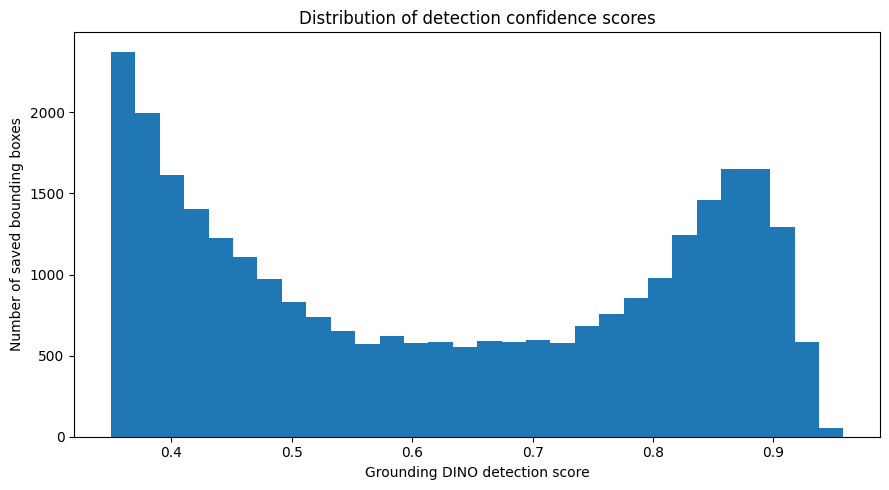

In [11]:

plt.figure(figsize=(9, 5))

plt.hist(
    boxes_df["score"].dropna(),
    bins=30
)

plt.xlabel("Grounding DINO detection score")
plt.ylabel("Number of saved bounding boxes")
plt.title("Distribution of detection confidence scores")

plt.tight_layout()
plt.show()


## Number of detections per image

,Images
n_detections,
0,567
1,17791
2,3207
3,1037
4,370
5,84
6,18
7,13
8,2


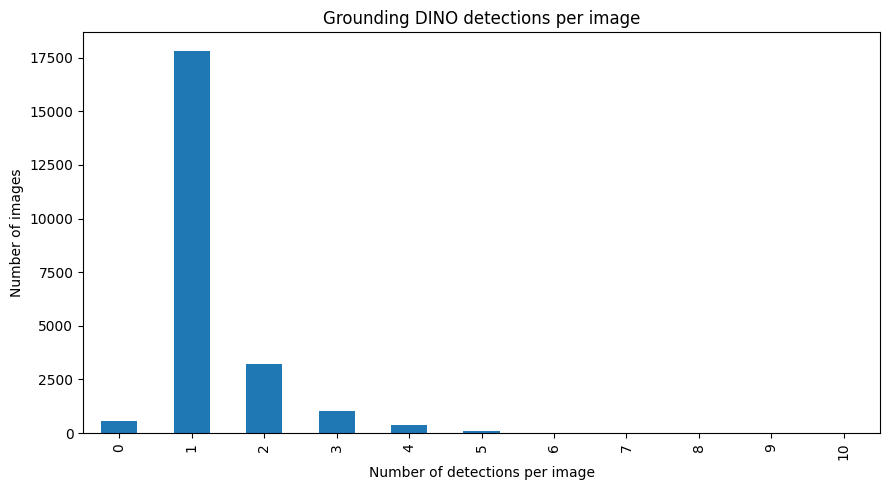

In [12]:

detection_counts = (
    manifest_df.loc[
        manifest_df["status"].isin(["completed", "no_detection"]),
        "n_detections"
    ]
    .astype(int)
)

count_distribution = (
    detection_counts.value_counts()
    .sort_index()
)

display(count_distribution.to_frame("Images"))

plt.figure(figsize=(9, 5))
count_distribution.plot(kind="bar")

plt.xlabel("Number of detections per image")
plt.ylabel("Number of images")
plt.title("Grounding DINO detections per image")

plt.tight_layout()
plt.show()


In [13]:
detections_df.columns

Index(['obs_id', 'photo_id', 'photo_license_code', 'photo_url', 'obs_url',
       'quality_grade', 'obs_license_code', 'predator_prey_role',
       'scientific_name', 'taxon_rank', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'photo_count', 'kingdom_name', 'phylum_name',
       'class_name', 'order_name', 'family_name', 'genus_name', 'species_name',
       'subspecies_name', 'subfamily_name', 'hybrid_name', 'complex_name',
       'form_name', 'subgenus_name', 'variety_name', 'tribe_name', 'country',
       'state', 'city', 'file_name', 'image_byte_size', 'image_local_path',
       'image_download_url', 'grounding_dino_prompt', 'source_row',
       'img_width', 'img_height', 'n_detections', 'max_score', 'mean_score',
       'detection_flag', 'prompt_used', 'rank', 'score', 'group', 'label',
       'x0', 'y0', 'x1', 'y1', 'box_area_frac', 'aspect_ratio',
       'edge_proximity_frac', 'center_offset_frac', 'is_valid_box',
       'score_rank_gap'],
      dtype='str

In [14]:
detections_df["rank"].describe()

count    29391.000000
mean         1.330986
std          0.688262
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          5.000000
Name: rank, dtype: float64

In [15]:
manifest_df.columns

Index(['source_row', 'photo_id', 'image_local_path', 'status', 'n_detections',
       'saved_boxes', 'checkpoint_file', 'error'],
      dtype='str')

In [16]:
manifest_df["n_detections"].describe()

count    23091.000000
mean         1.275389
std          0.721080
min          0.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         10.000000
Name: n_detections, dtype: float64

How is the n_detections till 10 but the rank till 5 - There were 10 detection, out of which top 5 ranks based on the score were stored

## Bounding-box geometry diagnostics

In [17]:

metric_columns = [
    "box_area_frac",
    "aspect_ratio",
    "edge_proximity_frac",
    "center_offset_frac",
    "score_rank_gap"
]

display(
    boxes_df[metric_columns].describe(
        percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
    ).T
)

print("Invalid bounding boxes:")
print((boxes_df["is_valid_box"] == False).sum())


,count,mean,std,min,5%,25%,50%,75%,95%,max
box_area_frac,29391.0,0.263219,0.243686,0.000398,0.007452,0.058391,0.185037,0.41729,0.755539,0.99998
aspect_ratio,29391.0,1.229504,0.716960,0.083100,0.494200,0.795950,1.067900,1.46820,2.459100,15.62930
edge_proximity_frac,29391.0,0.093345,0.075126,-0.009900,0.000800,0.024300,0.082700,0.15190,0.226250,0.31790
center_offset_frac,29391.0,0.088879,0.069336,0.000000,0.011400,0.036550,0.070700,0.12320,0.229850,0.44740
score_rank_gap,11600.0,0.209858,0.167549,0.000000,0.008400,0.053350,0.165600,0.36490,0.489710,0.58320


Invalid bounding boxes:
855


What do you mean by invalid bounding box? - Investigated later

## Identify potentially questionable detections

In [18]:

# Smallest boxes
small_boxes = boxes_df.nsmallest(
    20, "box_area_frac"
)

# Largest boxes
large_boxes = boxes_df.nlargest(
    20, "box_area_frac"
)

# Lowest-confidence retained boxes
low_scores = boxes_df.nsmallest(
    20, "score"
)

display(
    small_boxes[
        ["source_row", "photo_id", "rank",
         "score", "box_area_frac", "label"]
    ]
)


,source_row,photo_id,rank,score,box_area_frac,label
22708,17501,553836095,1,0.415618,0.000398,blue bird
16990,13122,403272212,3,0.355896,0.000433,sharp keel - shaped bill
13788,10657,333785060,2,0.391430,0.000465,sharp yellow bill
13795,10659,333785072,3,0.359792,0.000511,sharp yellow bill
13792,10658,333785064,3,0.382348,0.000515,sharp yellow bill
10142,7817,246419262,2,0.371441,0.000536,beak
16972,13113,403272551,3,0.498553,0.000547,sharp keel - shaped bill
7223,5564,173052489,3,0.371828,0.000571,small eyes
13909,10747,335190104,2,0.502982,0.000580,sharp hooked beak
24857,19076,605730843,3,0.353091,0.000611,distinctive white eye ring


In [19]:

top1_df = boxes_df.loc[
    boxes_df["rank"] == 1
].copy()

print("Top-1 detection labels:")
display(
    top1_df["label"]
    .value_counts()
    .head(30)
    .to_frame("Image count")
)


Top-1 detection labels:


,Image count
label,
brown bird,1557
black bird,1442
blue bird,1289
brown spider,604
brown butterfly,599
beetle,538
white bird,521
brown snake,455
spider,401


In [20]:
image_rank_gap = boxes_df.loc[
    boxes_df["rank"] == 1,
    "score_rank_gap"
].dropna()

display(
    image_rank_gap.describe(
        percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
    )
)

count    4733.000000
mean        0.206169
std         0.168465
min         0.000000
5%          0.008660
25%         0.052000
50%         0.156500
75%         0.362100
95%         0.493940
max         0.583200
Name: score_rank_gap, dtype: float64

## Investigate the 855 invalid bounding boxes

### Identify exactly why each box is invalid

In [21]:

invalid_df = boxes_df.loc[
    boxes_df["is_valid_box"] == False
].copy()

# Basic geometry
invalid_df["box_w"] = invalid_df["x1"] - invalid_df["x0"]
invalid_df["box_h"] = invalid_df["y1"] - invalid_df["y0"]

# Distance outside each image boundary, in pixels
invalid_df["left_over"] = (-invalid_df["x0"]).clip(lower=0)
invalid_df["top_over"] = (-invalid_df["y0"]).clip(lower=0)

invalid_df["right_over"] = (
    invalid_df["x1"] - invalid_df["img_width"]
).clip(lower=0)

invalid_df["bottom_over"] = (
    invalid_df["y1"] - invalid_df["img_height"]
).clip(lower=0)

overflow_cols = [
    "left_over", "top_over",
    "right_over", "bottom_over"
]

invalid_df["max_overflow_px"] = invalid_df[
    overflow_cols
].max(axis=1)

nonfinite = ~np.isfinite(
    invalid_df[["x0", "y0", "x1", "y1"]]
).all(axis=1)

bad_dimensions = (
    (invalid_df["box_w"] <= 0) |
    (invalid_df["box_h"] <= 0)
)

outside = invalid_df["max_overflow_px"] > 0

invalid_df["reason"] = np.select(
    [nonfinite, bad_dimensions, outside],
    [
        "Non-finite coordinates",
        "Non-positive dimensions",
        "Outside image boundaries"
    ],
    default="Other"
)

print("Invalid boxes:", len(invalid_df))
print("Affected images:", invalid_df["source_row"].nunique())

display(invalid_df["reason"].value_counts())

display(
    invalid_df["max_overflow_px"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)


Invalid boxes: 855
Affected images: 818


reason
Outside image boundaries    855
Name: count, dtype: int64

count    855.000000
mean       1.570148
std        1.592282
min        0.001709
50%        1.092163
90%        3.610010
95%        4.602887
99%        7.014904
max       14.309082
Name: max_overflow_px, dtype: float64

### Determine whether boundary clipping is sufficient

In [22]:

# Clip coordinates only for diagnostic comparison
invalid_df["clip_x0"] = invalid_df["x0"].clip(
    lower=0, upper=invalid_df["img_width"]
)
invalid_df["clip_y0"] = invalid_df["y0"].clip(
    lower=0, upper=invalid_df["img_height"]
)
invalid_df["clip_x1"] = invalid_df["x1"].clip(
    lower=0, upper=invalid_df["img_width"]
)
invalid_df["clip_y1"] = invalid_df["y1"].clip(
    lower=0, upper=invalid_df["img_height"]
)

invalid_df["clipped_valid"] = (
    np.isfinite(
        invalid_df[
            ["clip_x0", "clip_y0", "clip_x1", "clip_y1"]
        ]
    ).all(axis=1)
    & (invalid_df["clip_x1"] > invalid_df["clip_x0"])
    & (invalid_df["clip_y1"] > invalid_df["clip_y0"])
)

print("Recoverable after clipping:")
display(invalid_df["clipped_valid"].value_counts())

print("Overflow magnitude:")
display(
    pd.cut(
        invalid_df["max_overflow_px"],
        bins=[-0.001, 1, 5, 20, np.inf],
        labels=["≤1 px", "1–5 px", "5–20 px", ">20 px"]
    ).value_counts().sort_index()
)


Recoverable after clipping:


clipped_valid
True    855
Name: count, dtype: int64

Overflow magnitude:


max_overflow_px
≤1 px      406
1–5 px     417
5–20 px     32
>20 px       0
Name: count, dtype: int64

### Visually inspect invalid boxes

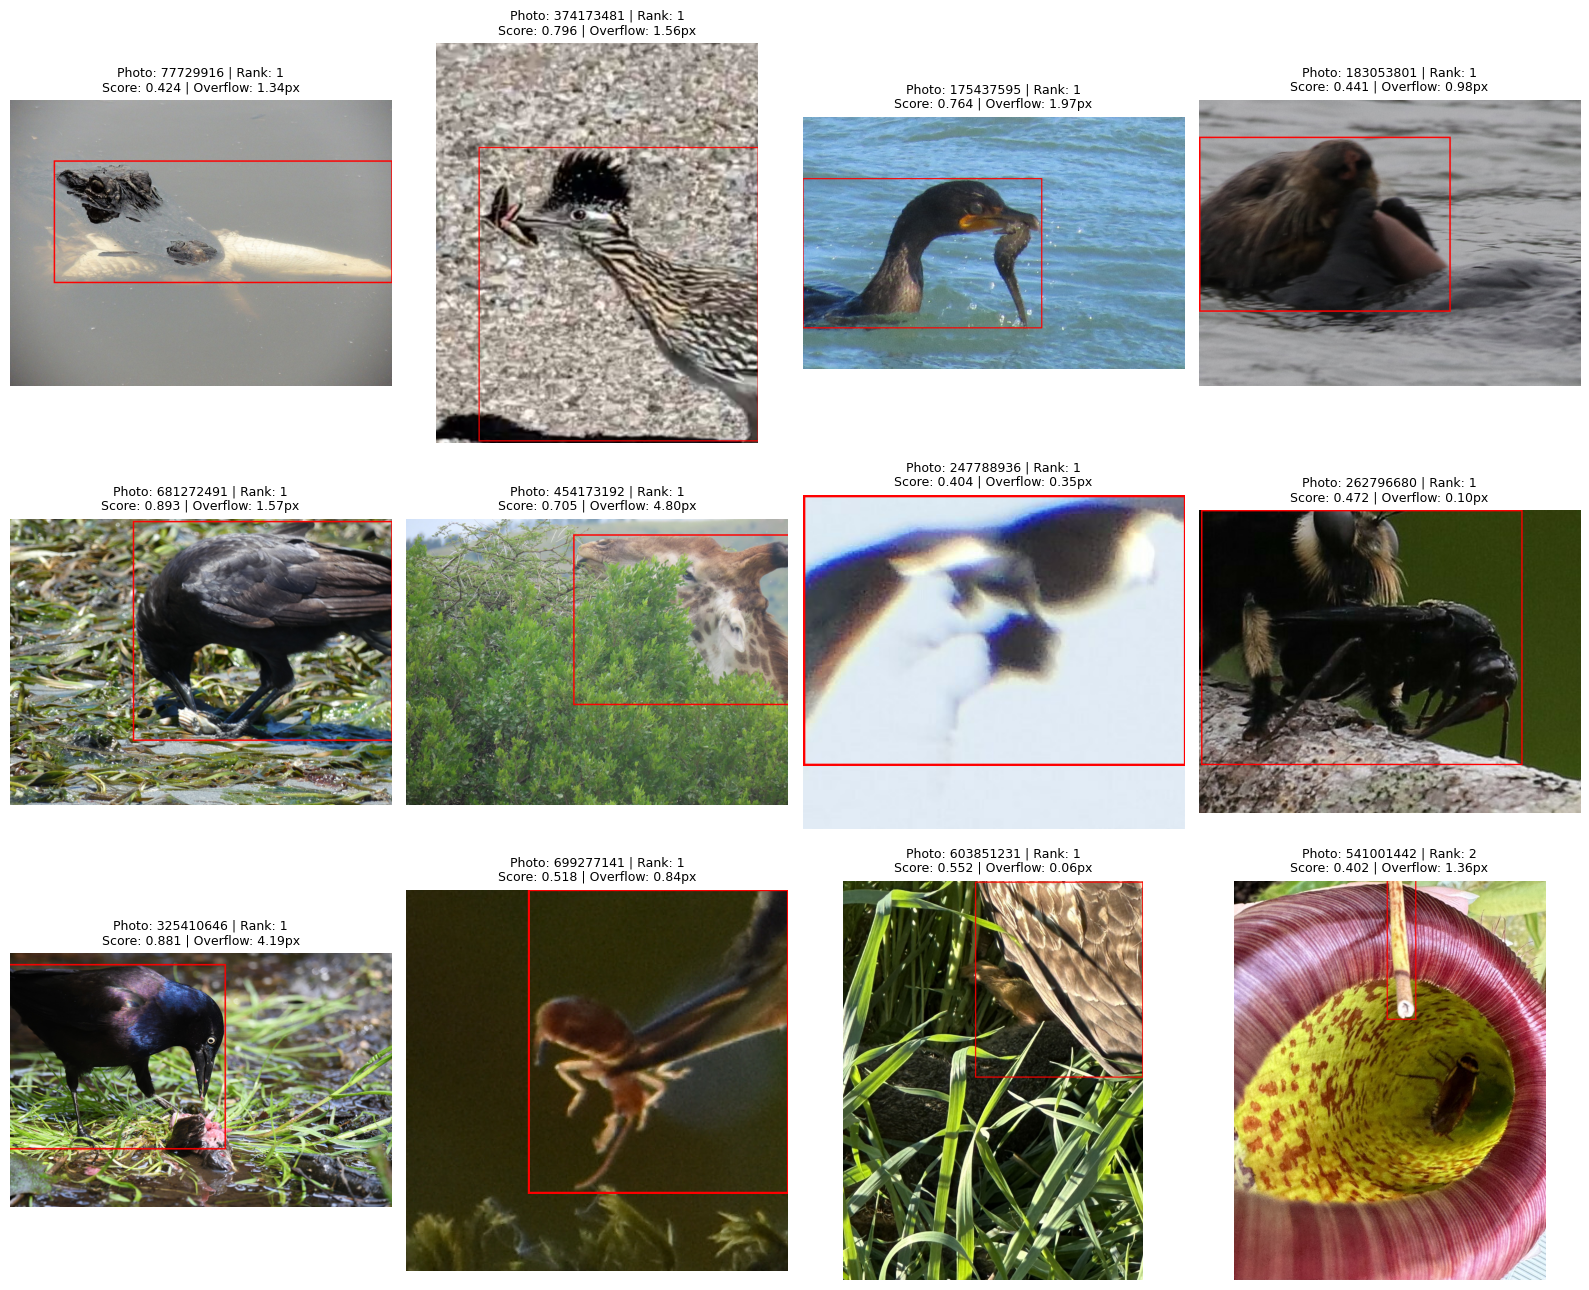

In [23]:

from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

def show_invalid_boxes(data, n=12, seed=42):
    sample = data.sample(
        min(n, len(data)), random_state=seed
    )

    fig, axes = plt.subplots(
        3, 4, figsize=(16, 13)
    )

    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        path = Path(str(row["image_local_path"]))

        if not path.is_file():
            ax.set_title("Image missing")
            ax.axis("off")
            continue

        with Image.open(path) as im:
            image = im.convert("RGB")

        draw = ImageDraw.Draw(image)
        draw.rectangle(
            [row["x0"], row["y0"], row["x1"], row["y1"]],
            outline="red",
            width=max(2, image.width // 250)
        )

        ax.imshow(image)
        ax.set_title(
            f"Photo: {row['photo_id']} | Rank: {row['rank']}\n"
            f"Score: {row['score']:.3f} | "
            f"Overflow: {row['max_overflow_px']:.2f}px",
            fontsize=9
        )
        ax.axis("off")

    for ax in axes.flat[len(sample):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_invalid_boxes(invalid_df)


I need to clip down and correct the cordinates so that i can the final data input file for bioclip

## Investigate the 567 no-detection images

### Extract the no-detection images

In [24]:

missed_df = detections_df.loc[
    detections_df["n_detections"] == 0
].copy()

print("No-detection images:", len(missed_df))
print("Unique images:", missed_df["source_row"].nunique())

display(
    missed_df[
        [
            "source_row",
            "photo_id",
            "scientific_name",
            "grounding_dino_prompt",
            "image_local_path"
        ]
    ].head(10)
)


No-detection images: 567
Unique images: 567


,source_row,photo_id,scientific_name,grounding_dino_prompt,image_local_path
9,5,28352912,Lycophidion capense,"brown snake with dark blotches, narrow head, a...",/rs1/researchers/a/amallav/species_classificat...
22,14,15885882,Dendroaspis polylepis,"black snake with black scales, narrow head, an...",/rs1/researchers/a/amallav/species_classificat...
78,52,12158042,Hippotragus niger niger,dark brown antelope with long straight horns a...,/rs1/researchers/a/amallav/species_classificat...
81,54,26880735,Panthera leo melanochaita,"golden cat with shaggy mane, short tawny coat,...",/rs1/researchers/a/amallav/species_classificat...
140,103,3467087,Telchinia burni,"yellow butterfly with brown edges, pale yellow...",/rs1/researchers/a/amallav/species_classificat...
262,192,8301050,Silurus glanis,"large catfish with long whisker-like barbels, ...",/rs1/researchers/a/amallav/species_classificat...
372,264,11871525,Crocuta crocuta,"brown mammal with spotted coat, long dog-like ...",/rs1/researchers/a/amallav/species_classificat...
375,266,11871572,Leptoptilos crumenifer,"large black bird with long neck, bare red head...",/rs1/researchers/a/amallav/species_classificat...
399,287,12637215,Stegodyphus dumicola,"brown spider with distinctive rounded abdomen,...",/rs1/researchers/a/amallav/species_classificat...
402,290,12637266,Stegodyphus dumicola,"brown spider with distinctive rounded abdomen,...",/rs1/researchers/a/amallav/species_classificat...


In [25]:

taxon_cols = [
    col for col in ["phylum", "class", "order", "family"]
    if col in detections_df.columns
]

for col in taxon_cols:
    print(f"\n{col.upper()}")

    all_counts = (
        detections_df[["source_row", col]]
        .drop_duplicates("source_row")[col]
        .value_counts()
    )

    missed_counts = missed_df[col].value_counts()

    summary = pd.DataFrame({
        "total_images": all_counts,
        "no_detection": missed_counts
    }).fillna(0)

    summary["no_detection_rate_pct"] = (
        100 * summary["no_detection"]
        / summary["total_images"]
    )

    display(
        summary.loc[summary["total_images"] >= 20]
        .sort_values(
            "no_detection_rate_pct",
            ascending=False
        )
        .head(15)
    )


### Visually inspect missed images with their prompts

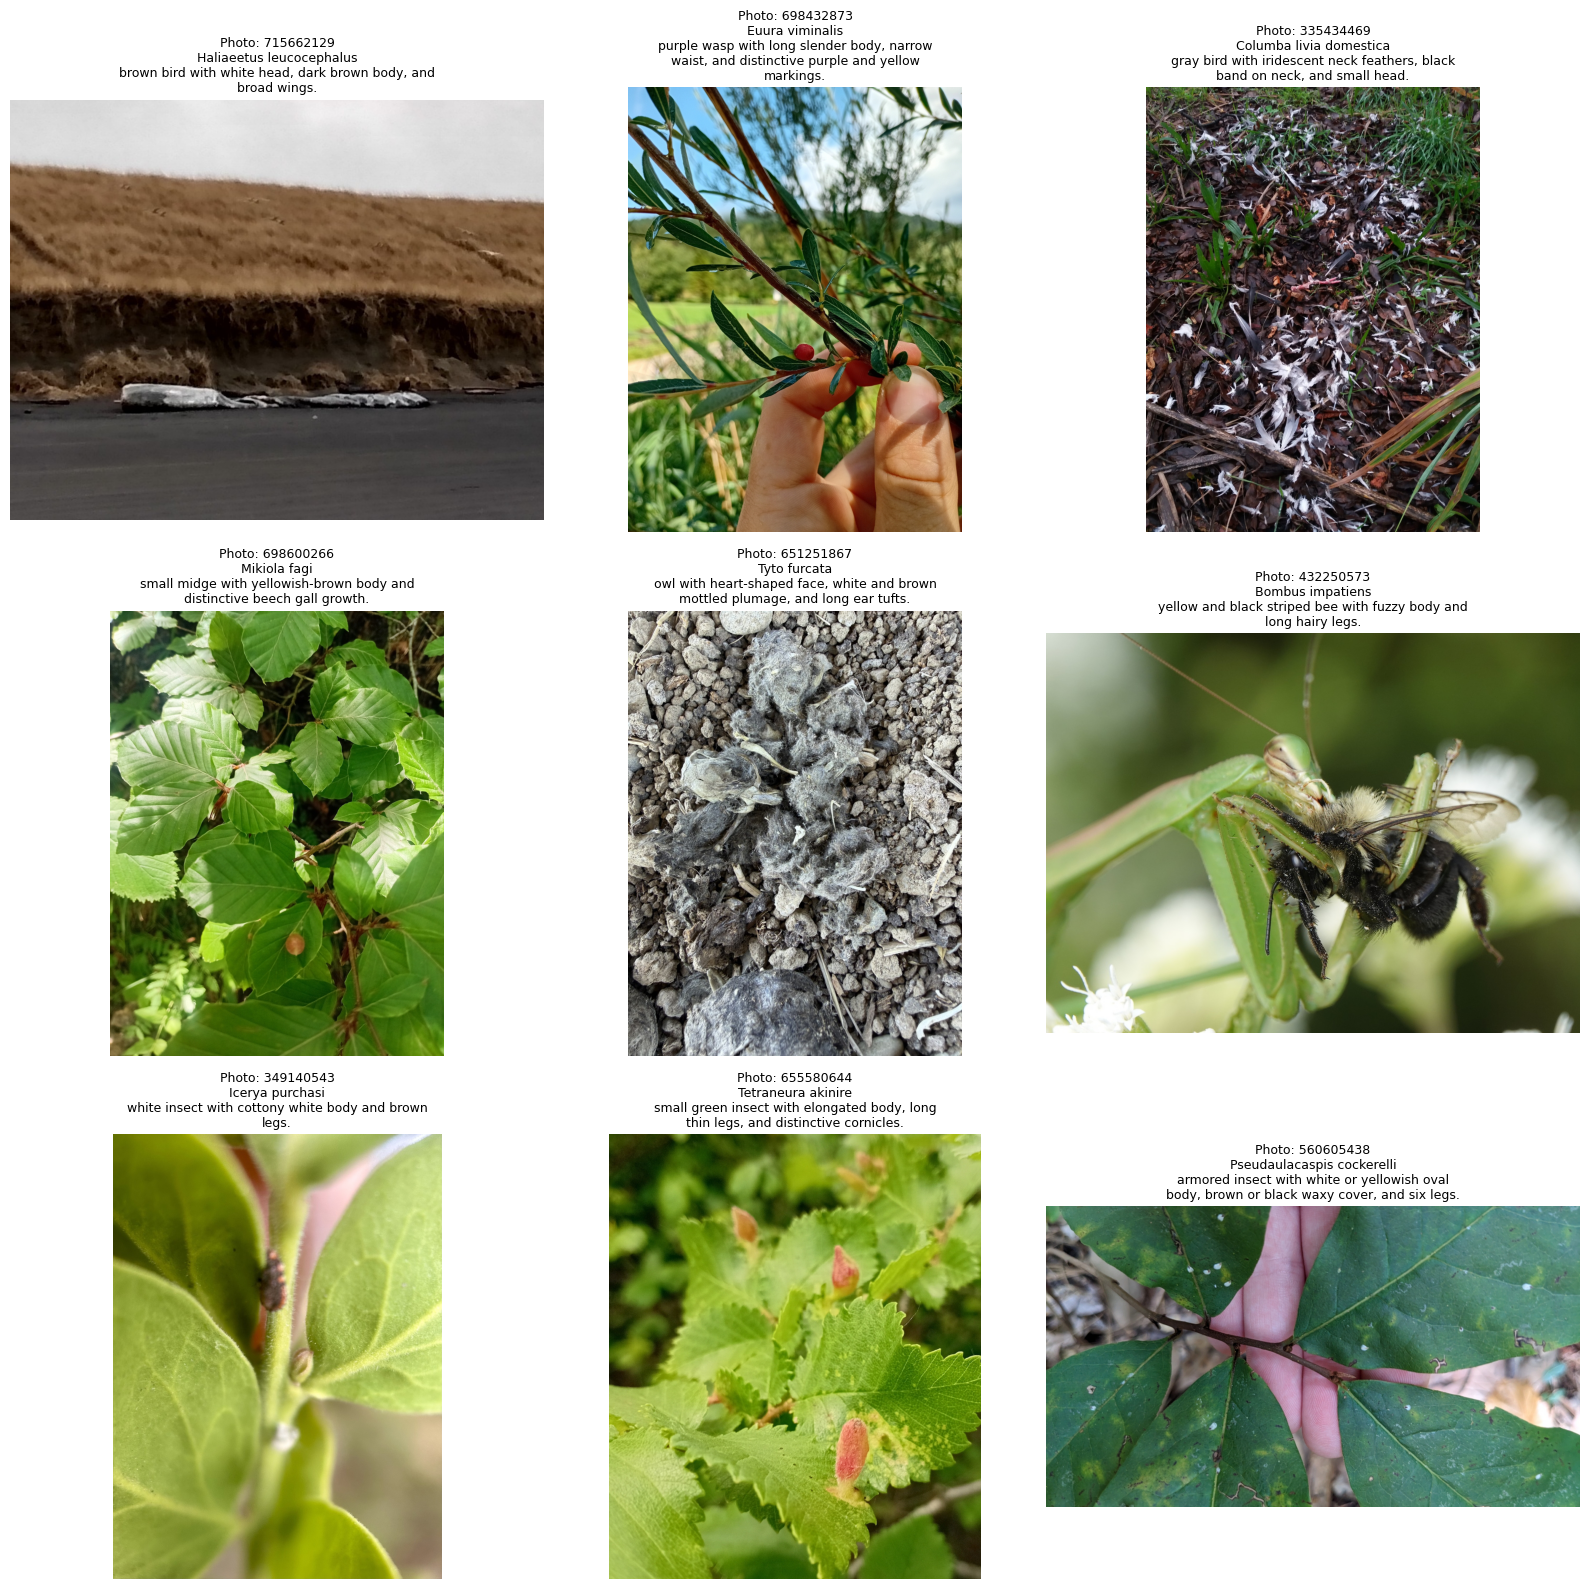

In [26]:

from textwrap import fill

def show_missed_images(data, n=9, seed=42):
    sample = data.sample(
        min(n, len(data)), random_state=seed
    )

    fig, axes = plt.subplots(3, 3, figsize=(16, 16))

    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        path = Path(str(row["image_local_path"]))

        if not path.is_file():
            ax.set_title("Image missing")
            ax.axis("off")
            continue

        with Image.open(path) as im:
            image = im.convert("RGB")

        ax.imshow(image)

        prompt = str(row["grounding_dino_prompt"])

        ax.set_title(
            f"Photo: {row['photo_id']}\n"
            f"{row['scientific_name']}\n"
            f"{fill(prompt[:150], width=48)}",
            fontsize=9
        )
        ax.axis("off")

    for ax in axes.flat[len(sample):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_missed_images(missed_df)


I need to later look into all the images - 567 images to note down why each failed. This will be done post bioclip 

# Generate corrected crop coordinates

In [27]:

# Start with actual detections only
bioclip_input = boxes_df.copy()


In [28]:

# Create corrected crop coordinates separately.

bioclip_input["crop_x0"] = np.floor(
    bioclip_input["x0"].clip(lower=0)
)

bioclip_input["crop_y0"] = np.floor(
    bioclip_input["y0"].clip(lower=0)
)

bioclip_input["crop_x1"] = np.ceil(
    np.minimum(
        bioclip_input["x1"],
        bioclip_input["img_width"]
    )
)

bioclip_input["crop_y1"] = np.ceil(
    np.minimum(
        bioclip_input["y1"],
        bioclip_input["img_height"]
    )
)


In [29]:

# Enforce all image boundaries
bioclip_input["crop_x0"] = np.maximum(
    bioclip_input["crop_x0"], 0
)
bioclip_input["crop_y0"] = np.maximum(
    bioclip_input["crop_y0"], 0
)

bioclip_input["crop_x1"] = np.minimum(
    bioclip_input["crop_x1"],
    bioclip_input["img_width"]
)

bioclip_input["crop_y1"] = np.minimum(
    bioclip_input["crop_y1"],
    bioclip_input["img_height"]
)

crop_cols = ["crop_x0", "crop_y0", "crop_x1", "crop_y1"]


In [30]:

# Reject non-finite or empty crops before converting to integer
finite = np.isfinite(
    bioclip_input[crop_cols]
).all(axis=1)

positive_area = (
    (bioclip_input["crop_x1"] > bioclip_input["crop_x0"])
    & (bioclip_input["crop_y1"] > bioclip_input["crop_y0"])
)

bioclip_input["crop_valid"] = finite & positive_area


In [31]:

# Record whether original coordinates required boundary correction
bioclip_input["was_out_of_bounds"] = (
    bioclip_input["is_valid_box"] == False
)

print("Total detections:", len(bioclip_input))
print("Valid crops:", bioclip_input["crop_valid"].sum())
print("Invalid crops:", (~bioclip_input["crop_valid"]).sum())
print("Original out-of-bounds boxes:",
      bioclip_input["was_out_of_bounds"].sum())


Total detections: 29391
Valid crops: 29391
Invalid crops: 0
Original out-of-bounds boxes: 855


In [32]:

# Keep only usable crops
bioclip_input = bioclip_input.loc[
    bioclip_input["crop_valid"]
].copy()

bioclip_input[crop_cols] = (
    bioclip_input[crop_cols].astype("int64")
)


In [33]:
bioclip_input.columns

Index(['obs_id', 'photo_id', 'photo_license_code', 'photo_url', 'obs_url',
       'quality_grade', 'obs_license_code', 'predator_prey_role',
       'scientific_name', 'taxon_rank', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'photo_count', 'kingdom_name', 'phylum_name',
       'class_name', 'order_name', 'family_name', 'genus_name', 'species_name',
       'subspecies_name', 'subfamily_name', 'hybrid_name', 'complex_name',
       'form_name', 'subgenus_name', 'variety_name', 'tribe_name', 'country',
       'state', 'city', 'file_name', 'image_byte_size', 'image_local_path',
       'image_download_url', 'grounding_dino_prompt', 'source_row',
       'img_width', 'img_height', 'n_detections', 'max_score', 'mean_score',
       'detection_flag', 'prompt_used', 'rank', 'score', 'group', 'label',
       'x0', 'y0', 'x1', 'y1', 'box_area_frac', 'aspect_ratio',
       'edge_proximity_frac', 'center_offset_frac', 'is_valid_box',
       'score_rank_gap', 'crop_x0', 'crop_

In [34]:

assert bioclip_input["crop_valid"].all()

assert (bioclip_input["crop_x0"] >= 0).all()
assert (bioclip_input["crop_y0"] >= 0).all()

assert (
    bioclip_input["crop_x1"] <= bioclip_input["img_width"]
).all()

assert (
    bioclip_input["crop_y1"] <= bioclip_input["img_height"]
).all()

assert (
    bioclip_input["crop_x1"] > bioclip_input["crop_x0"]
).all()

assert (
    bioclip_input["crop_y1"] > bioclip_input["crop_y0"]
).all()

assert not bioclip_input.duplicated(
    ["source_row", "rank"]
).any()

print("Validated BioCLIP input:", len(bioclip_input))
print("Unique images:", bioclip_input["source_row"].nunique())


Validated BioCLIP input: 29391
Unique images: 22524


In [35]:

BIOCLIP_INPUT_PATH = (
    ANALYSIS_DIR / "bioclip2_input_detections.parquet"
)

MISSED_PATH = (
    ANALYSIS_DIR / "grounding_dino_no_detections.parquet"
)

bioclip_input.to_parquet(
    BIOCLIP_INPUT_PATH,
    index=False
)

missed_df.to_parquet(
    MISSED_PATH,
    index=False
)

print("BioCLIP input:", BIOCLIP_INPUT_PATH)
print("No-detection dataset:", MISSED_PATH)


BioCLIP input: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/object_detection/output/analysis/bioclip2_input_detections.parquet
No-detection dataset: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/object_detection/output/analysis/grounding_dino_no_detections.parquet
